# Exploratory Data Analysis — Italian Electricity Prices (2024)

This notebook explores historical hourly electricity prices, validates temporal coverage and daylight-saving-time transitions, and produces descriptive visualizations. It is an exploratory analysis, not a forecasting evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the project dataset
data_path = Path("../data/Anno 2024_12.xlsx")


if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {data_path.resolve()}\n"
        "Place the source Excel file in the project's data/ directory."
    )

# Load historical electricity prices
df = pd.read_excel(
    data_path,
    sheet_name = "Prezzi-Prices"
)

# Select the relevant columns
prices = df.iloc[:,[0,1,2]].copy()
prices.columns = ['date','hour','price']

#Convert "date" to data type
prices['date'] = pd.to_datetime(prices['date'].astype(str),format='%Y%m%d')

# Initial data quality checks
print("Number of rows:", len(prices))

print("\nMissing values:")
print(prices.isna().sum())

print("\nData types:")
print(prices.dtypes)

Number of rows: 8784

Missing values:
date     0
hour     0
price    0
dtype: int64

Data types:
date     datetime64[ns]
hour              int64
price           float64
dtype: object


In [2]:
# Validate the hourly time-series structure
daily_counts = prices.groupby("date").size()

print("Number of unique days:", prices["date"].nunique())
print("First date:", prices["date"].min())
print("Last date:", prices["date"].max())

print("\nObservations per day:")
print(daily_counts.value_counts().sort_index())

print("\nDuplicate date-hour pairs:")
print(prices.duplicated(subset=["date", "hour"]).sum())

print("\nDays with a number of observations different from 24:")
print(daily_counts[daily_counts != 24])


Number of unique days: 366
First date: 2024-01-01 00:00:00
Last date: 2024-12-31 00:00:00

Observations per day:
23      1
24    364
25      1
Name: count, dtype: int64

Duplicate date-hour pairs:
0

Days with a number of observations different from 24:
date
2024-03-31    23
2024-10-27    25
dtype: int64


### Time-Series Data Validation

The dataset contains 8,784 hourly electricity price observations covering all 366 days of 2024.

Data quality checks confirmed:

- No missing values in the date, hour, or price columns.
- No duplicate date-hour combinations.
- 364 days with 24 observations.
- One day with 23 observations (March 31, 2024).
- One day with 25 observations (October 27, 2024).

The two irregular days correspond to daylight saving time transitions in Italy and are retained in the dataset.

These checks are important for ensuring consistent temporal alignment during feature engineering and future integration of external electricity market data.

### Descriptive statistics

The summary below reports the distribution of hourly electricity prices in EUR/MWh.

In [3]:
prices['price'].describe()

count    8784.000000
mean      108.523696
std        29.656853
min         0.100000
25%        92.042115
50%       105.827185
75%       122.040000
max       275.123710
Name: price, dtype: float64

### Daily average prices

Daily averages highlight how the price level varies throughout 2024. The chart is descriptive and does not use future information for prediction.

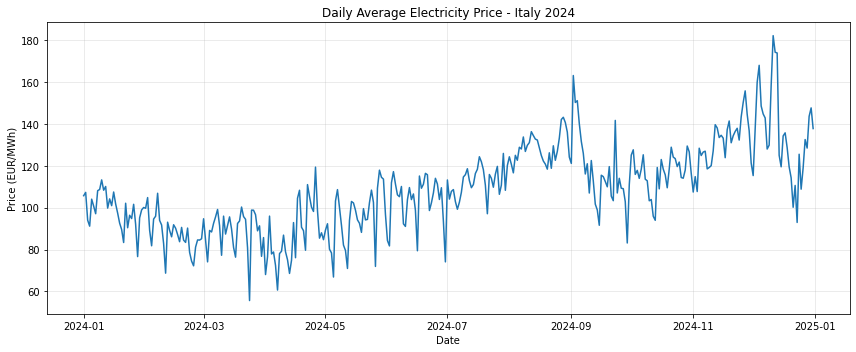

In [4]:
# Daily average electricity price

daily_prices = prices.groupby('date').price.mean()


#Plot

plt.figure(figsize=(12,5))

plt.plot(daily_prices.index, daily_prices.values)

plt.title('Daily Average Electricity Price - Italy 2024')
plt.xlabel('Date')
plt.ylabel('Price (EUR/MWh)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Intraday price patterns

Mean prices are grouped by the source dataset’s hour labels. The extra hour on the autumn daylight-saving transition is retained.

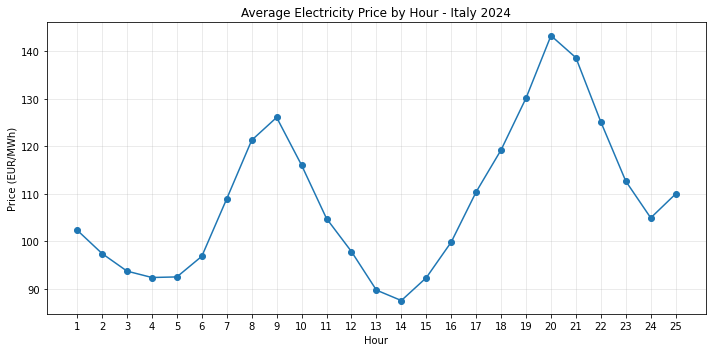

In [5]:
# Average electricity price by hour
hourly_price = prices.groupby('hour').price.mean()

plt.figure(figsize=(10,5))

plt.plot(hourly_price.index, hourly_price.values, marker='o')
plt.title('Average Electricity Price by Hour - Italy 2024')
plt.xlabel('Hour')
plt.ylabel('Price (EUR/MWh)')

plt.xticks(hourly_price.index)  # Includes hour 25 on the DST transition
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Day-of-week patterns

The day-of-week comparison summarizes differences between weekdays and weekends.

In [6]:
# # Average electricity price by day of the week

prices["day_of_week"] = prices["date"].dt.dayofweek

weekly_prices = prices.groupby('day_of_week').price.mean()

print(weekly_prices)


day_of_week
0    111.886627
1    112.484545
2    114.213767
3    111.195141
4    110.025156
5    102.520208
6     97.199582
Name: price, dtype: float64


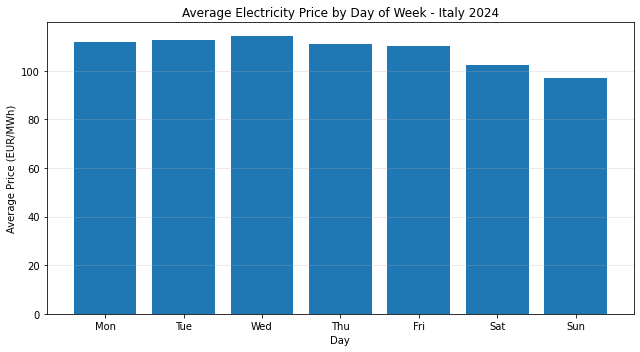

In [7]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(9,5))

plt.bar(days,weekly_prices.values)

plt.title("Average Electricity Price by Day of Week - Italy 2024")
plt.xlabel('Day')
plt.ylabel("Average Price (EUR/MWh)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Hour-by-weekday heatmap

The heatmap combines hour labels and day of week. DST-related hour 25 is shown separately rather than silently discarded.

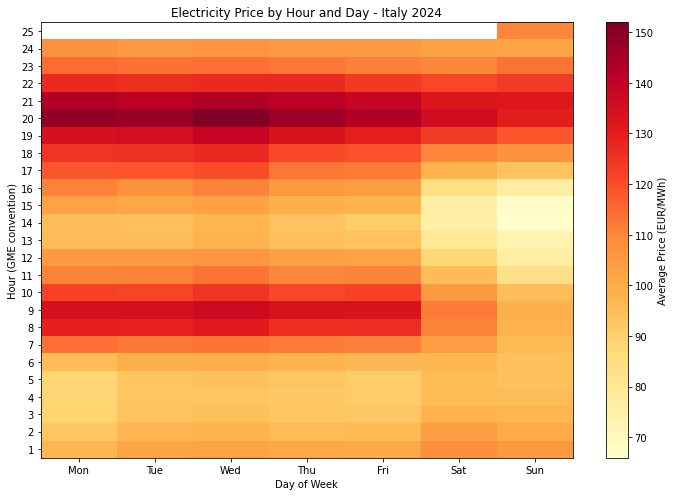

In [8]:
# Combine day and hour

hour_day_table = prices.pivot_table(
    values = 'price',
    index = 'hour',
    columns = 'day_of_week',
    aggfunc = 'mean'
)


# heat_map plot

plt.figure(figsize=(10,7))

plt.imshow(
    hour_day_table,
    aspect="auto",
    cmap="YlOrRd",
    origin="lower"
)

plt.colorbar(label="Average Price (EUR/MWh)")


plt.xticks(
    range(7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.yticks(
    range(len(hour_day_table.index)),  # Includes DST hour 25
    hour_day_table.index
)

plt.xlabel("Day of Week")
plt.ylabel("Hour (GME convention)")
plt.title("Electricity Price by Hour and Day - Italy 2024")

plt.tight_layout()
plt.show()

### Local export

Export the prepared data for later experiments. The CSV is written locally to `data/`; this does not imply permission to redistribute the original market data.

In [9]:
# Save the prepared dataset to the project data directory.
# The dataset is for local use; do not publish it without checking source terms.
output_path = Path("../data/electricity_prices_2024.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
prices.to_csv(output_path, index=False)
print(f"Saved prepared dataset to: {output_path.resolve()}")

Saved prepared dataset to: C:\Users\Prota\Desktop\DataScience\Italian-electricity-price-forecasting\data\electricity_prices_2024.csv
